# Market Risk Check: How Much Could a Stock Portfolio Lose in a Day?

**The question:** If I put ₹10 lakh into 5 big Indian stocks, what is the most I could lose on a really bad day, and was that guess right in the past?

**Three ideas, in plain words:**
- **Value at Risk (VaR):** "On 99 days out of 100, I won't lose more than ₹X." Banks use this number every day.
- **Expected Shortfall:** "On that 1 bad day in 100, how much do I lose on average?"
- **Back-testing:** checking the past to see whether our VaR guess was actually right. Banks report this to regulators using the **Basel traffic-light test**.
- **Stress test:** "What happened on the worst days ever, and would our model have coped?" We use the COVID crash of March 2020.

In [1]:

!pip install yfinance -q

import yfinance as yf        # downloads stock prices
import pandas as pd          # works with tables
import numpy as np           # does maths
import matplotlib.pyplot as plt   # draws charts

In [2]:
#  6 years of daily closing prices for 5 big Indian companies
# (starting in 2019 so we include the COVID crash of March 2020)
stocks = ["RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "INFY.NS", "ITC.NS"]

prices = yf.download(stocks, start="2019-01-01", end="2025-01-01", auto_adjust=True)["Close"]
prices = prices.dropna()

print("Days of data:", len(prices))
prices.tail()

[*********************100%***********************]  5 of 5 completed

Days of data: 1481


Ticker,HDFCBANK.NS,INFY.NS,ITC.NS,RELIANCE.NS,TCS.NS
Date,,,,,
2024-12-24,872.626892,1774.259644,424.632233,1212.280762,3871.898193
2024-12-26,869.059875,1772.726196,423.300934,1206.133911,3862.264160
2024-12-27,872.699707,1781.416016,424.765350,1210.595459,3858.327148
2024-12-30,862.823730,1771.425049,423.345367,1200.333984,3852.721436
2024-12-31,860.372925,1747.260620,429.247314,1205.043213,3793.432373


##  Daily returns
A **return** is how much the price moved in a day. If a stock goes from ₹100 to ₹102, the return is +2%.
Our portfolio has the same money in each stock, so the portfolio return is just the **average** of the 5 returns.

In [3]:
returns = prices.pct_change().dropna()        # daily % change of each stock
portfolio = returns.mean(axis=1)               # equal money in each stock -> simple average

print("Average daily return:", round(portfolio.mean() * 100, 3), "%")
print("Worst day:", round(portfolio.min() * 100, 2), "%")
print("Best day: ", round(portfolio.max() * 100, 2), "%")

Average daily return: 0.072 %
Worst day: -11.0 %
Best day:  8.1 %


## Value at Risk
- **Historical method:** line up every past day from worst to best and take the worst 1%. No assumptions.
- **Normal-curve method:** assume returns follow a bell curve. 99% VaR = average − 2.33 × standard deviation.

**Expected Shortfall** = the average of all the days that were worse than VaR.

In [4]:
money = 1_000_000   # ₹10 lakh portfolio

var_historical = portfolio.quantile(0.01)                     # worst 1% of days
var_normal     = portfolio.mean() - 2.33 * portfolio.std()    # bell-curve method
expected_shortfall = portfolio[portfolio <= var_historical].mean()   # average of the worst days

results = pd.DataFrame({
    "Daily loss (%)": [var_historical * 100, var_normal * 100, expected_shortfall * 100],
    "Loss on ₹10 lakh (₹)": [var_historical * money, var_normal * money, expected_shortfall * money],
}, index=["99% VaR (Historical)", "99% VaR (Normal curve)", "Expected Shortfall"]).round(2)

results

,Daily loss (%),Loss on ₹10 lakh (₹)
99% VaR (Historical),-3.03,-30321.09
99% VaR (Normal curve),-2.59,-25850.16
Expected Shortfall,-4.95,-49542.60


##Back-testing 1.1
Every day, we calculate VaR using **only the previous 250 trading days** (about 1 year), just like a bank would.
Then we look at the next day. If the real loss was bigger than VaR, that's a **breach**.

At 99%, we expect about **2.5 breaches in 250 days**. The Basel rules say:
- **0–4 breaches → Green** (model is fine)
- **5–9 breaches → Amber** (model is doubtful, bank holds extra capital)
- **10+ breaches → Red** (model is not trusted)

In [5]:
window = 250   # one year of trading days

# VaR for each day, using only the 250 days before it
rolling_var_hist   = portfolio.rolling(window).quantile(0.01).shift(1)
rolling_var_normal = (portfolio.rolling(window).mean() - 2.33 * portfolio.rolling(window).std()).shift(1)

test = pd.DataFrame({"return": portfolio,
                     "var_hist": rolling_var_hist,
                     "var_normal": rolling_var_normal}).dropna()

test["breach_hist"]   = test["return"] < test["var_hist"]
test["breach_normal"] = test["return"] < test["var_normal"]

def traffic_light(breaches):
    if breaches <= 4:
        return "GREEN"
    elif breaches <= 9:
        return "AMBER"
    return "RED"

last_year = test.tail(250)   # Basel looks at the most recent 250 days
summary = pd.DataFrame({
    "Breaches (last 250 days)": [last_year["breach_hist"].sum(), last_year["breach_normal"].sum()],
    "Expected": [2.5, 2.5],
}, index=["Historical VaR", "Normal-curve VaR"])
summary["Basel zone"] = summary["Breaches (last 250 days)"].apply(traffic_light)

summary

,Breaches (last 250 days),Expected,Basel zone
Historical VaR,4,2.5,GREEN
Normal-curve VaR,5,2.5,AMBER


## the back-test 1.2
Banks must keep money aside (**capital**) to cover trading losses. Under the Basel rules, a simplified version is:

**Capital = VaR × multiplier**

The multiplier depends on the back-test. A model that breaks more often is trusted less, so the bank must hold more:

| Breaches | Zone | Multiplier |
|---|---|---|
| 0–4 | Green | 3.0 |
| 5 / 6 / 7 / 8 / 9 | Amber | 3.4 / 3.5 / 3.65 / 3.75 / 3.85 |
| 10+ | Red | 4.0 |

In [6]:
def multiplier(breaches):
    amber = {5: 3.4, 6: 3.5, 7: 3.65, 8: 3.75, 9: 3.85}
    if breaches <= 4:
        return 3.0
    return amber.get(breaches, 4.0)

capital = summary.copy()
capital["Multiplier"] = capital["Breaches (last 250 days)"].apply(multiplier)
capital["Latest VaR (₹)"] = [round(abs(test["var_hist"].iloc[-1] * money)), round(abs(test["var_normal"].iloc[-1] * money))]
capital["Capital to hold (₹)"] = (capital["Latest VaR (₹)"] * capital["Multiplier"]).round(0)

capital

,Breaches (last 250 days),Expected,Basel zone,Multiplier,Latest VaR (₹),Capital to hold (₹)
Historical VaR,4,2.5,GREEN,3.0,21053,63159.0
Normal-curve VaR,5,2.5,AMBER,3.4,19451,66133.0


#Stress test
VaR is built on normal times. A **stress test** asks: what happened on the worst days ever, and how far off was our model?
We find the portfolio's worst day and worst week, and compare the worst day with what VaR predicted **the day before**.

In [7]:
worst_date = test["return"].idxmin()                    # the single worst day
worst_day  = test.loc[worst_date, "return"]
predicted  = test.loc[worst_date, "var_hist"]           # what VaR said the day before
worst_week = portfolio.rolling(5).sum().min()           # worst 5 days in a row
breaches_2020 = int(test.loc["2020", "breach_hist"].sum())

print("Worst day:", worst_date.date())
print(f"  Real loss:      ₹{abs(worst_day * money):,.0f}")
print(f"  VaR predicted:  ₹{abs(predicted * money):,.0f}")
print(f"  The real loss was {worst_day / predicted:.1f} times bigger than VaR expected.")
print(f"Worst week loss:  ₹{abs(worst_week * money):,.0f}")
print(f"Breaches in 2020: {breaches_2020} -> {traffic_light(breaches_2020)} zone")

Worst day: 2020-03-23
  Real loss:      ₹109,974
  VaR predicted:  ₹45,899
  The real loss was 2.4 times bigger than VaR expected.
Worst week loss:  ₹192,905
Breaches in 2020: 6 -> AMBER zone


#REPRESENTATION
Grey line = real daily returns. Blue line = our VaR limit. **Red dots = days the loss was worse than VaR.**

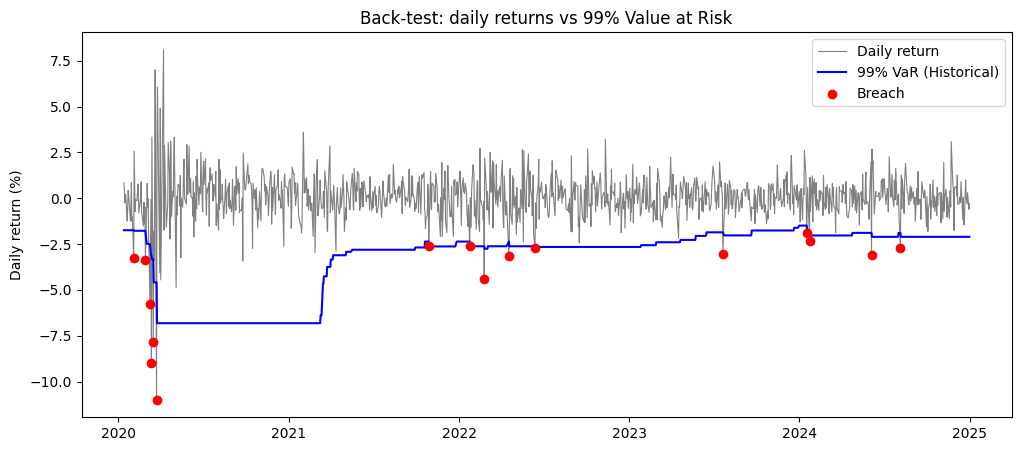

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(test.index, test["return"] * 100, color="grey", linewidth=0.8, label="Daily return")
plt.plot(test.index, test["var_hist"] * 100, color="blue", label="99% VaR (Historical)")

breaches = test[test["breach_hist"]]
plt.scatter(breaches.index, breaches["return"] * 100, color="red", zorder=3, label="Breach")

plt.title("Back-test: daily returns vs 99% Value at Risk")
plt.ylabel("Daily return (%)")
plt.legend()
plt.show()

#FINAL CONCLUSIONS

In [9]:
hist_b = int(last_year["breach_hist"].sum())
norm_b = int(last_year["breach_normal"].sum())

print(f"On a ₹10 lakh portfolio, a 1-in-100 bad day costs about ₹{abs(var_historical * money):,.0f} (historical VaR).")
print(f"On those worst days, the average loss is about ₹{abs(expected_shortfall * money):,.0f} (Expected Shortfall).")
print(f"Back-test over the last 250 days: Historical VaR had {hist_b} breaches ({traffic_light(hist_b)}), "
      f"Normal-curve VaR had {norm_b} breaches ({traffic_light(norm_b)}).")

if norm_b > hist_b:
    print("The normal-curve method broke more often: real markets have more extreme days than a bell curve expects.")
elif hist_b > norm_b:
    print("The historical method broke more often: the recent year was rougher than the past it learned from.")
else:
    print("Both methods performed the same over this period.")

print(f"Stress test: on {worst_date.date()} the portfolio lost ₹{abs(worst_day * money):,.0f}, "
      f"{worst_day / predicted:.1f} times what VaR predicted. In 2020 the model was in the {traffic_light(breaches_2020)} zone.")
print("Lesson: VaR covers normal bad days; stress tests are needed for the extreme ones.")

print(f"Capital to hold under the Basel rule: ₹{capital['Capital to hold (₹)'].iloc[0]:,.0f} (historical) vs "
      f"₹{capital['Capital to hold (₹)'].iloc[1]:,.0f} (normal curve).")

On a ₹10 lakh portfolio, a 1-in-100 bad day costs about ₹30,321 (historical VaR).
On those worst days, the average loss is about ₹49,543 (Expected Shortfall).
Back-test over the last 250 days: Historical VaR had 4 breaches (GREEN), Normal-curve VaR had 5 breaches (AMBER).
The normal-curve method broke more often: real markets have more extreme days than a bell curve expects.
Stress test: on 2020-03-23 the portfolio lost ₹109,974, 2.4 times what VaR predicted. In 2020 the model was in the AMBER zone.
Lesson: VaR covers normal bad days; stress tests are needed for the extreme ones.
Capital to hold under the Basel rule: ₹63,159 (historical) vs ₹66,133 (normal curve).
